In [11]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Files:", [p.name for p in Path.cwd().iterdir()])

Current directory: C:\Users\manil\Python Project
Files: ['.ipynb_checkpoints', 'FloridaCountyBoundarieswithFDOTDistricts.cpg', 'FloridaCountyBoundarieswithFDOTDistricts.dbf', 'FloridaCountyBoundarieswithFDOTDistricts.prj', 'FloridaCountyBoundarieswithFDOTDistricts.shp', 'FloridaCountyBoundarieswithFDOTDistricts.shx', 'R-working.ipynb', 'STORM_DATA_EC-Earth3P-HR_NA_1000_YEARS_1_IBTRACSDELTA.txt']


In [21]:
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path

# Locate files relative to the notebook
data_dir = Path.cwd()
print("Current folder:", data_dir)

# 1. Read hurricane file
colnames = [
    "Year", "Month", "TCnumber", "TimeStep", "BasinID",
    "Latitude", "Longitude", "MinimumPressure", "MaximumWindSpeed",
    "RadiusToMaximumWinds", "Category", "Landfall", "DistanceToLand"
]

storm_file = data_dir / "STORM_DATA_EC-Earth3P-HR_NA_1000_YEARS_1_IBTRACSDELTA.txt"

df = pd.read_csv(
    storm_file,
    header=None,
    names=colnames,
    skipinitialspace=True
)

# Convert longitude to [-180, 180]
df["Lon180"] = ((df["Longitude"] + 180) % 360) - 180

# Create geographic points
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["Lon180"], df["Latitude"]),
    crs="EPSG:4326"
)

# 2. Read Florida shapefile
shapefile = data_dir / "FloridaCountyBoundarieswithFDOTDistricts.shp"

florida = gpd.read_file(shapefile)
florida = florida.to_crs(epsg=4326)

# Combine county polygons
florida_state = florida.dissolve()

# 3. Select hurricane points inside Florida
is_in_florida = gdf.geometry.within(
    florida_state.geometry.iloc[0]
)

florida_points = gdf[is_in_florida].copy()

print("Number of hurricane points inside Florida:", len(florida_points))
print(florida_points.head())


Current folder: C:\Users\manil\Python Project
Number of hurricane points inside Florida: 1058
      Year  Month  TCnumber  TimeStep  BasinID  Latitude  Longitude  \
71     0.0    9.0       0.0      71.0      1.0      29.8      274.9   
72     0.0    9.0       0.0      72.0      1.0      30.4      275.4   
2751  11.0    9.0       1.0       3.0      1.0      26.5      279.3   
2752  11.0    9.0       1.0       4.0      1.0      26.6      278.8   
2753  11.0    9.0       1.0       5.0      1.0      26.6      278.4   

      MinimumPressure  MaximumWindSpeed  RadiusToMaximumWinds  Category  \
71              996.8         18.935811             40.743999       0.0   
72              999.6         16.729027             40.743999       0.0   
2751            990.1         23.500000             27.780001       0.0   
2752            994.5         20.300000             27.780001       0.0   
2753           1000.1         16.000000             27.780001       0.0   

      Landfall  DistanceToLa

**Fresh start**

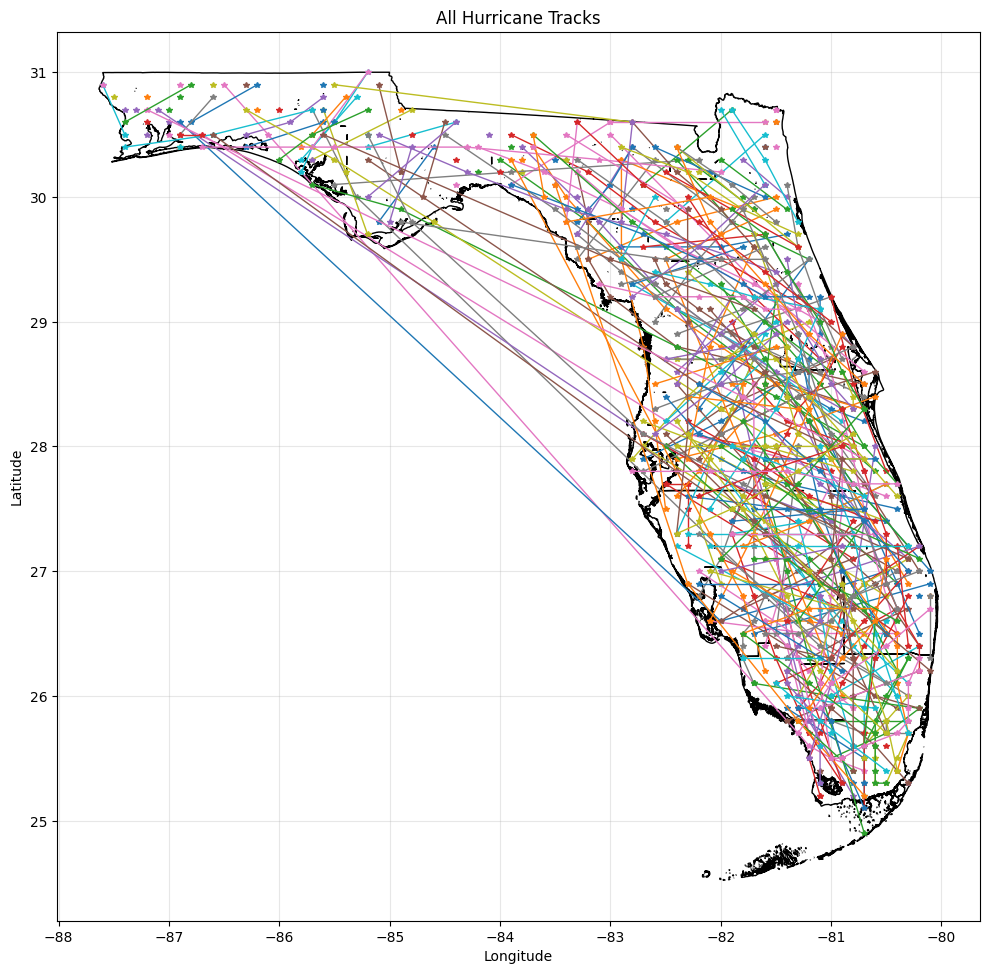

In [13]:
import matplotlib.pyplot as plt

# sort so each track is drawn in the correct order
florida_points = florida_points.sort_values(["Year", "TCnumber", "TimeStep"]).copy()

fig, ax = plt.subplots(figsize=(10, 10))

# Florida boundary
florida_state.boundary.plot(ax=ax, color="black", linewidth=1)

# plot one line per hurricane track
for (year, tcnum), hcane in florida_points.groupby(["Year", "TCnumber"]):
    ax.plot(
        hcane.geometry.x,
        hcane.geometry.y,
        "-*",
        linewidth=1,
        markersize=4
    )


ax.set_title("All Hurricane Tracks")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Visualize Sample Hurricane

In [14]:
sampleYear = 11
sampleTCnum = 1
sampleind = florida_points[(florida_points["Year"]==sampleYear) & (florida_points["TCnumber"]==sampleTCnum)]
print(sampleind)

      Year  Month  TCnumber  TimeStep  BasinID  Latitude  Longitude  \
2751  11.0    9.0       1.0       3.0      1.0      26.5      279.3   
2752  11.0    9.0       1.0       4.0      1.0      26.6      278.8   
2753  11.0    9.0       1.0       5.0      1.0      26.6      278.4   

      MinimumPressure  MaximumWindSpeed  RadiusToMaximumWinds  Category  \
2751            990.1              23.5             27.780001       0.0   
2752            994.5              20.3             27.780001       0.0   
2753           1000.1              16.0             27.780001       0.0   

      Landfall  DistanceToLand  Lon180            geometry  
2751       1.0             0.0   -80.7  POINT (-80.7 26.5)  
2752       1.0             0.0   -81.2  POINT (-81.2 26.6)  
2753       1.0             0.0   -81.6  POINT (-81.6 26.6)  


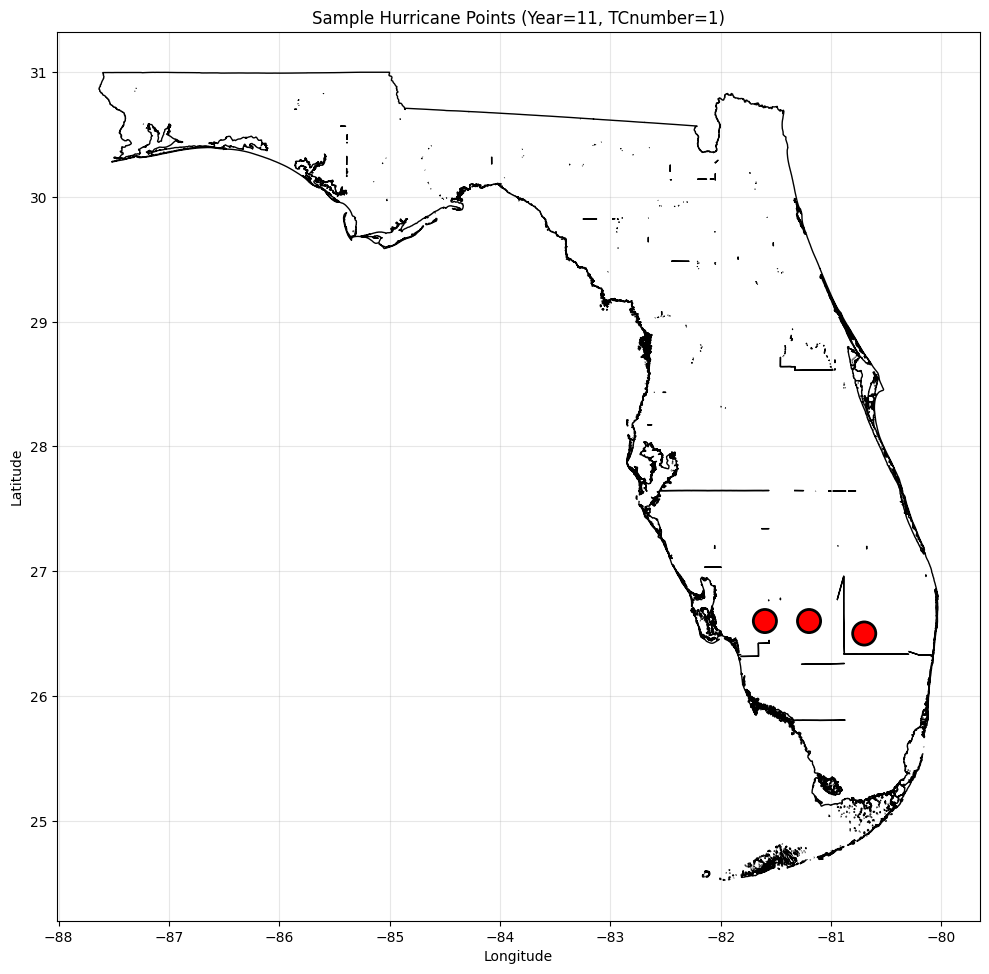

In [15]:
fig, ax = plt.subplots(figsize=(10, 10))

# Florida boundary
florida_state.boundary.plot(ax=ax, color="black", linewidth=1)

plt.scatter(
    sampleind.geometry.x,   
    sampleind.geometry.y,   
    s=sampleind['RadiusToMaximumWinds'] * 10,  # Makes the circle size equal to the radius (scaled by 5 for visibility)
    marker="o", 
    facecolors="r", 
    edgecolors="black",         
    linewidths=2             
)

ax.set_title(f"Sample Hurricane Points (Year={sampleYear}, TCnumber={sampleTCnum})")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Geocoding 1/18: 911 Easterwood Dr, Tallahassee, FL
  Success!
Geocoding 2/18: 3226 Flastacowo Rd, Tallahassee, FL
  Failed - address needs review
Geocoding 3/18: 3840 N Monroe St, Tallahassee, FL
  Success!
Geocoding 4/18: 5300 Interbay Blvd, Tampa, FL
  Success!
Geocoding 5/18: 3804 E 26th Ave, Tampa, FL
  Success!
Geocoding 6/18: 11001 N 15th St, Tampa, FL
  Success!
Geocoding 7/18: 370 Zoo Pkwy, Jacksonville, FL
  Success!
Geocoding 8/18: 117 W Duval St, Jacksonville, FL
  Success!
Geocoding 9/18: 3625 University Blvd S, Jacksonville, FL
  Success!
Geocoding 10/18: 224 SE 24th St, Gainesville, FL
  Success!
Geocoding 11/18: 803 NW 192nd Ave, Gainesville, FL
  Failed - address needs review
Geocoding 12/18: 309 Village Dr, Gainesville, FL
  Success!
Geocoding 13/18: 11805 SW 26th St, Miami, FL
  Success!
Geocoding 14/18: 3500 Pan American Dr, Miami, FL
  Success!
Geocoding 15/18: 11380 NW 27th Ave, Miami, FL
  Success!
Geocoding 16/18: 5100 L B McLeod Rd, Orlando, FL
  Success!
Geocod

,Address,MatchedAddress,Latitude,Longitude
0,"911 Easterwood Dr, Tallahassee, FL","Public Safety Complex, 911, Easterwood Drive, ...",30.451425,-84.222793
1,"3226 Flastacowo Rd, Tallahassee, FL",NaN,NaN,NaN
2,"3840 N Monroe St, Tallahassee, FL","North Monroe Street, Tallahassee, Leon County,...",30.462522,-84.281864
3,"5300 Interbay Blvd, Tampa, FL","5300, Interbay Boulevard, Tampa, Hillsborough ...",27.889568,-82.482103
4,"3804 E 26th Ave, Tampa, FL","3804, East 26th Avenue, East Ybor, Tampa, Hill...",27.974201,-82.415815
5,"11001 N 15th St, Tampa, FL","11001, North 15th Street, Sulphur Springs, Tam...",28.051063,-82.442783
6,"370 Zoo Pkwy, Jacksonville, FL","Jacksonville Zoo and Gardens, 370, Zoo Parkway...",30.402285,-81.643262
7,"117 W Duval St, Jacksonville, FL","117, West Duval Street, Jacksonville, Duval Co...",30.330076,-81.659021
8,"3625 University Blvd S, Jacksonville, FL","Memorial Hospital, 3625, University Boulevard ...",30.287926,-81.601124
9,"224 SE 24th St, Gainesville, FL","224, Southeast 24th Street, Gainesville, Alach...",29.649472,-82.293409


Number of property assets inside Florida: 15
                              Address  \
0  911 Easterwood Dr, Tallahassee, FL   
2   3840 N Monroe St, Tallahassee, FL   
3       5300 Interbay Blvd, Tampa, FL   
4          3804 E 26th Ave, Tampa, FL   
5          11001 N 15th St, Tampa, FL   

                                      MatchedAddress  AssetValues  \
0  Public Safety Complex, 911, Easterwood Drive, ...       554500   
2  North Monroe Street, Tallahassee, Leon County,...       554500   
3  5300, Interbay Boulevard, Tampa, Hillsborough ...       460000   
4  3804, East 26th Avenue, East Ybor, Tampa, Hill...       460000   
5  11001, North 15th Street, Sulphur Springs, Tam...       460000   

   DistanceToSea  
0             35  
2             35  
3              5  
4              5  
5              5  


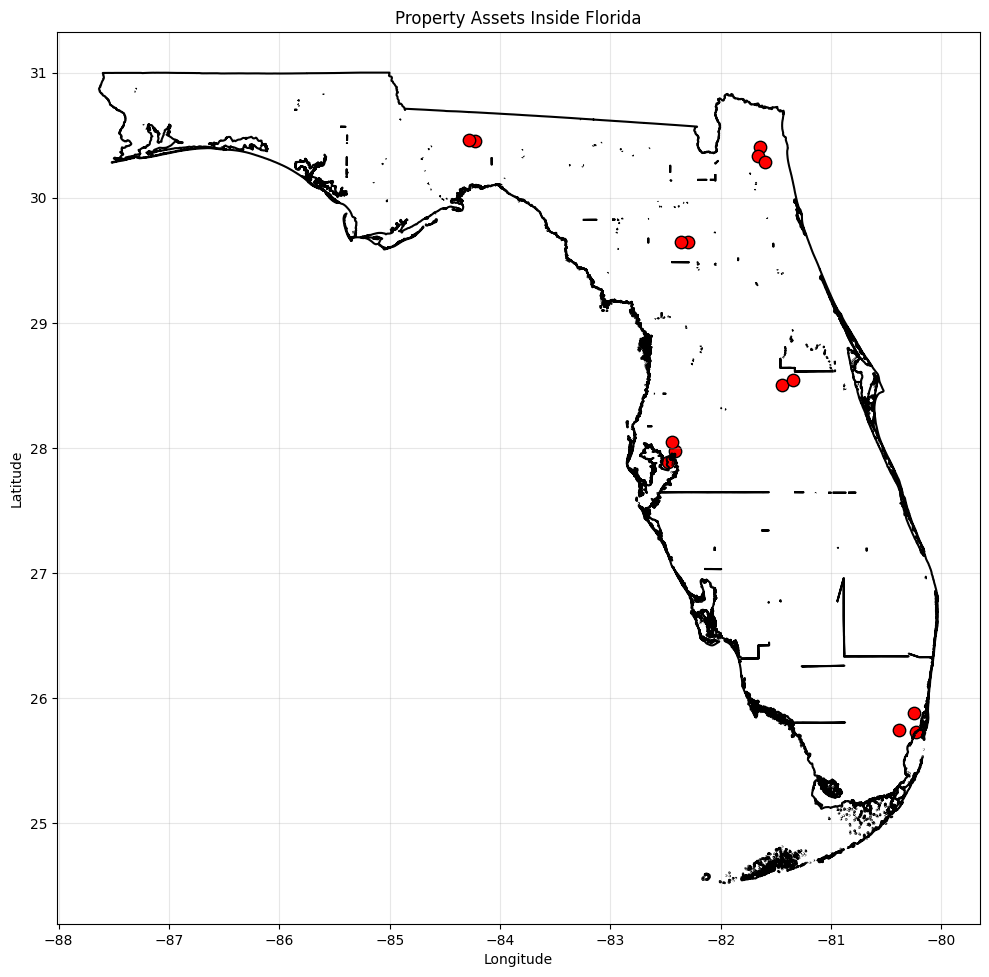

In [17]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from geopy.geocoders import Nominatim
from shapely.geometry import Point
import time

# -------------------------------------------------
# 1. Property addresses
# -------------------------------------------------
addresses = [
    "911 Easterwood Dr, Tallahassee, FL",
    "3226 Flastacowo Rd, Tallahassee, FL",
    "3840 N Monroe St, Tallahassee, FL",
    "5300 Interbay Blvd, Tampa, FL",
    "3804 E 26th Ave, Tampa, FL",
    "11001 N 15th St, Tampa, FL",
    "370 Zoo Pkwy, Jacksonville, FL",
    "117 W Duval St, Jacksonville, FL",
    "3625 University Blvd S, Jacksonville, FL",
    "224 SE 24th St, Gainesville, FL",
    "803 NW 192nd Ave, Gainesville, FL",
    "309 Village Dr, Gainesville, FL",
    "11805 SW 26th St, Miami, FL",
    "3500 Pan American Dr, Miami, FL",
    "11380 NW 27th Ave, Miami, FL",
    "5100 L B McLeod Rd, Orlando, FL",
    "595 N Primrose Dr, Orlando, FL",
    "6501 Magic Way, Orlando, FL"
]

# -------------------------------------------------
# 2. Geocode addresses
# -------------------------------------------------

from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import pandas as pd
from pathlib import Path

# Initialize geocoder with a longer timeout
geolocator = Nominatim(
    user_agent="florida_hurricane_risk_research",
    timeout=15
)

# Automatically retry failed requests
geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1.1,
    max_retries=3,
    error_wait_seconds=5,
    swallow_exceptions=True
)

# Save successful results so reruns don't repeat them
cache_file = Path("geocoded_assets.csv")

if cache_file.exists():
    cached = pd.read_csv(cache_file)
    cache = {
        row["Address"]: row
        for _, row in cached.dropna(
            subset=["Latitude", "Longitude"]
        ).iterrows()
    }
else:
    cache = {}

rows = []

for i, address in enumerate(addresses, 1):

    print(f"Geocoding {i}/{len(addresses)}: {address}")

    if address in cache:
        print("  Loaded from cache")
        result = {
            "Address": address,
            "MatchedAddress": cache[address]["MatchedAddress"],
            "Latitude": cache[address]["Latitude"],
            "Longitude": cache[address]["Longitude"]
        }
    else:
        location = geocode(address)

        if location is not None:
            result = {
                "Address": address,
                "MatchedAddress": location.address,
                "Latitude": location.latitude,
                "Longitude": location.longitude
            }
            print("  Success!")
        else:
            result = {
                "Address": address,
                "MatchedAddress": None,
                "Latitude": None,
                "Longitude": None
            }
            print("  Failed - address needs review")

    rows.append(result)

    # Save progress after every address
    pd.DataFrame(rows).to_csv(cache_file, index=False)

assets = pd.DataFrame(rows)

print("\nGeocoding completed!")
print("Successful:", assets["Latitude"].notna().sum())
print("Failed:", assets["Latitude"].isna().sum())

display(assets)


# -------------------------------------------------
# 3. Add asset values and distance to sea
# -------------------------------------------------
assets["AssetValues"] = [554500]*3 + [460000]*3 + [301000]*3 + [315000]*3 + [699000]*3 + [399000]*3
assets["DistanceToSea"] = [35]*3 + [5]*3 + [20]*3 + [80]*3 + [5]*3 + [55]*3

# -------------------------------------------------
# 4. Remove rows where geocoding failed
# -------------------------------------------------
assets = assets.dropna(subset=["Latitude", "Longitude"]).copy()

# -------------------------------------------------
# 5. Convert assets to GeoDataFrame
# -------------------------------------------------
assets_gdf = gpd.GeoDataFrame(
    assets,
    geometry=gpd.points_from_xy(assets["Longitude"], assets["Latitude"]),
    crs="EPSG:4326"
)

# -------------------------------------------------
# 6. Read Florida shapefile
# -------------------------------------------------
florida = gpd.read_file("FloridaCountyBoundarieswithFDOTDistricts.shp")

# convert to WGS84 if needed
florida = florida.to_crs(epsg=4326)

# dissolve all counties into one Florida polygon
florida_state = florida.dissolve()

# -------------------------------------------------
# 7. Keep only assets inside Florida
# -------------------------------------------------
is_in_florida = assets_gdf.geometry.within(florida_state.geometry.iloc[0])
florida_assets = assets_gdf[is_in_florida].copy()

print("Number of property assets inside Florida:", len(florida_assets))
print(florida_assets[["Address", "MatchedAddress", "AssetValues", "DistanceToSea"]].head())

# -------------------------------------------------
# 8. Plot Florida outline + property assets
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 10))

# Florida boundary
florida_state.boundary.plot(ax=ax, color="black", linewidth=1.5)

# Property assets
florida_assets.plot(
    ax=ax,
    color="red",
    edgecolor="black",
    markersize=80,
    marker="o"
)

ax.set_title("Property Assets Inside Florida")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
print(assets[["Address", "Latitude", "Longitude"]])

                                     Address   Latitude  Longitude
0         911 Easterwood Dr, Tallahassee, FL  30.451425 -84.222793
2          3840 N Monroe St, Tallahassee, FL  30.462522 -84.281864
3              5300 Interbay Blvd, Tampa, FL  27.889568 -82.482103
4                 3804 E 26th Ave, Tampa, FL  27.974201 -82.415815
5                 11001 N 15th St, Tampa, FL  28.051063 -82.442783
6             370 Zoo Pkwy, Jacksonville, FL  30.402285 -81.643262
7           117 W Duval St, Jacksonville, FL  30.330076 -81.659021
8   3625 University Blvd S, Jacksonville, FL  30.287926 -81.601124
9            224 SE 24th St, Gainesville, FL  29.649472 -82.293409
11           309 Village Dr, Gainesville, FL  29.648985 -82.359100
12               11805 SW 26th St, Miami, FL  25.747604 -80.385965
13           3500 Pan American Dr, Miami, FL  25.727755 -80.233811
14              11380 NW 27th Ave, Miami, FL  25.877940 -80.245659
15           5100 L B McLeod Rd, Orlando, FL  28.504665 -81.44

In [24]:
import numpy as np

In [25]:
def propertyDamage(v,vthresh,vhalf):
    w=np.maximum(v-vthresh,0)/(vhalf-vthresh)
    D=(w**3/(1+w**3))*100
    return D

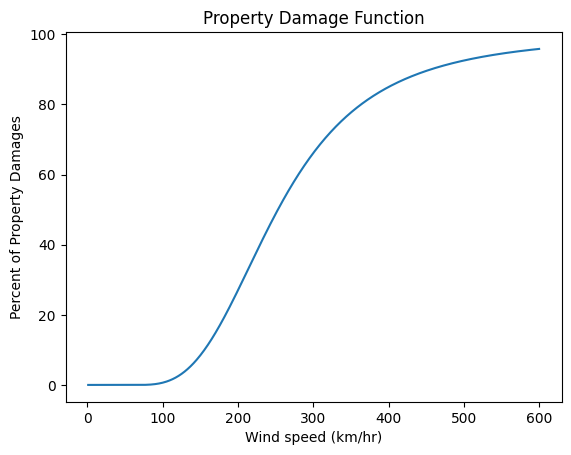

In [26]:
v=np.arange(1,601)
vthresh=65
vhalf=253
damage=propertyDamage(v,vthresh,vhalf)
plt.xlabel("Wind speed (km/hr)")
plt.ylabel("Percent of Property Damages")
plt.title("Property Damage Function")
plt.plot(v,damage)

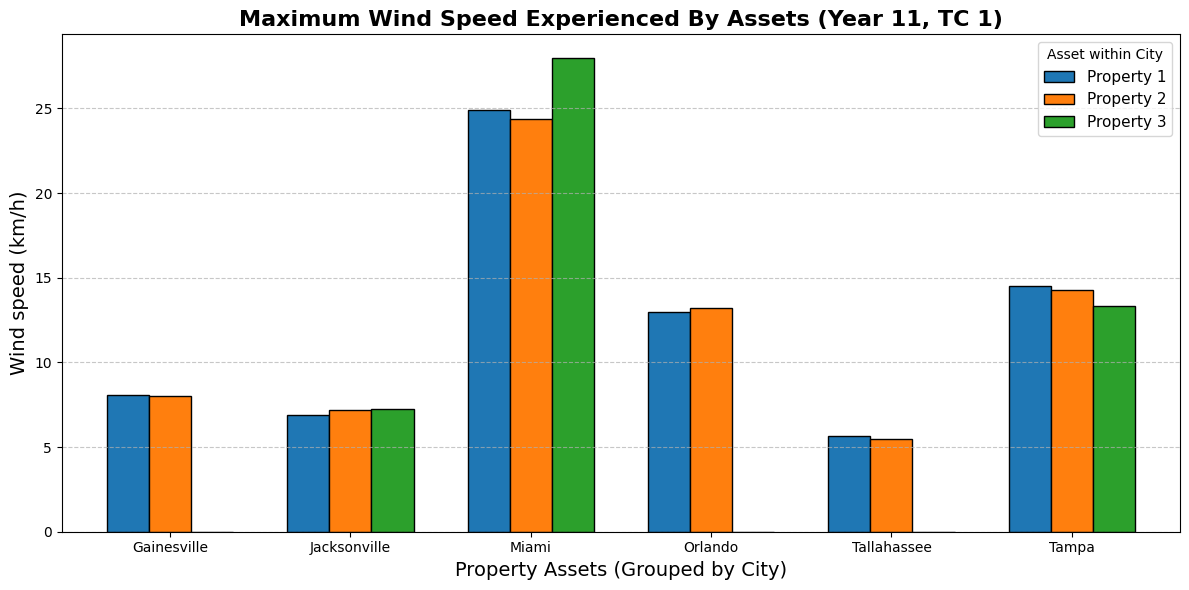

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. PREP DATA: Calculate Distance to Sea for all properties
# ---------------------------------------------------------
florida_m = florida_state.to_crs(epsg=3857)
florida_assets['DistanceToSea'] = florida_assets.to_crs(epsg=3857).distance(florida_m.boundary.iloc[0])

# ---------------------------------------------------------
# 2. DEFINE PHYSICS MODEL: Holland Wind Speed Equation
# ---------------------------------------------------------
def calculate_max_wind_speed(track, assets, dt_hours=3.0):
    if len(track) == 0: return np.zeros(len(assets))
    
    # Project to meters for accurate distance math
    track_m, assets_m = track.to_crs(epsg=3857), assets.to_crs(epsg=3857)
    asset_x, asset_y = assets_m.geometry.x.values, assets_m.geometry.y.values
    asset_lat = np.abs(assets.geometry.y.values)
    
    # Friction Parameter (F)
    R = 0.14 + 0.14 * np.clip(assets['DistanceToSea'].values / 50000.0, 0, 1) # 50,000m = 50km
    F = 0.7 * (1 - R)
    
    # Storm Movement & Pressure Arrays
    x_curr, y_curr = track_m.geometry.x.values, track_m.geometry.y.values
    pc = track['MinimumPressure'].values
    
    # Calculate storm forward speed and pressure changes
    if len(track) > 1:
        dx, dy, dp_dt = np.gradient(x_curr), np.gradient(y_curr), np.gradient(pc) / dt_hours
    else:
        dx, dy, dp_dt = np.zeros_like(x_curr), np.zeros_like(y_curr), np.zeros_like(pc)
        
    vt_ms = np.sqrt(dx**2 + dy**2) / (dt_hours * 3600)  
    vfor_kmh = vt_ms * 3.6                    
    theta_for = np.arctan2(dy, dx)
    
    vmax_kmh = track['MaximumWindSpeed'].values * 3.6 
    radm_km = track['RadiusToMaximumWinds'].values
    max_wind = np.zeros(len(assets))
    
    # Calculate physics for each time step
    for t in range(len(track)):
        dx_a, dy_a = asset_x - x_curr[t], asset_y - y_curr[t]
        radi_km = np.sqrt(dx_a**2 + dy_a**2) / 1000.0
        Ti = theta_for[t] - np.arctan2(dy_a, dx_a)
        
        dp = 1016.0 - pc[t]
        x_exp = 0.6 * (1 - (dp / 215.0))
        Bs = -4.4e-5*(dp**2) + 0.01*dp + 0.03*dp_dt[t] - 0.014*asset_lat + 0.15*(vt_ms[t]**x_exp) + 1.0
        B = 1.6 * Bs
        
        ratio = radm_km[t] / np.where(radi_km == 0, 1.0, radi_km)
        term1 = 1.5 * F * (vmax_kmh[t] - 0.5 * 1.0 * (1 - np.sin(Ti)) * vfor_kmh[t])
        
        with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
            v_step = np.nan_to_num(term1 * np.sqrt((ratio**B) * np.exp(1 - ratio**B)))
            max_wind = np.maximum(max_wind, np.where(radi_km == 0, 0, v_step))
            
    return max_wind

# ---------------------------------------------------------
# 3. RUN CALCULATION: Apply model to Year 11, TC 1
# ---------------------------------------------------------
sampleYear, sampleTCnum = 11, 1

# Filter for the specific storm while it is over Florida, sorted by time
sample_hcane = gdf[(gdf['Year'] == sampleYear) & 
                   (gdf['TCnumber'] == sampleTCnum) & 
                   gdf.geometry.within(florida_state.geometry.iloc[0])].sort_values('TimeStep')

# Calculate Winds and Damage
florida_assets['MaxWind'] = calculate_max_wind_speed(sample_hcane, florida_assets)
florida_assets['DamageProportion'] = propertyDamage(florida_assets['MaxWind'], 65, 253)

# ---------------------------------------------------------
# 4. PLOT: Grouped Bar Chart
# ---------------------------------------------------------
# Group assets by city
addr_col = 'address' if 'address' in florida_assets.columns else 'Address'
florida_assets['City'] = florida_assets[addr_col].apply(lambda x: x.split(',')[1].strip())
florida_assets['PropertyIndex'] = florida_assets.groupby('City').cumcount() + 1

# Pivot for graphing
pivot_table = florida_assets.pivot(index='City', columns='PropertyIndex', values='MaxWind')

# Draw Chart
ax = pivot_table.plot(kind='bar', figsize=(12, 6), edgecolor='black', width=0.7)
ax.set_title(f"Maximum Wind Speed Experienced By Assets (Year {sampleYear}, TC {sampleTCnum})", fontsize=16, fontweight='bold')
ax.set_ylabel("Wind speed (km/h)", fontsize=14)
ax.set_xlabel("Property Assets (Grouped by City)", fontsize=14)
ax.legend(title="Asset within City", labels=['Property 1', 'Property 2', 'Property 3'], fontsize=11)
plt.xticks(rotation=0)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [27]:
# Calculate property loss for the sample hurricane
florida_assets["PropertyLoss"] = (
    florida_assets["DamageProportion"] / 100
    * florida_assets["AssetValues"]
)

display(florida_assets[
    ["Address", "AssetValues", "MaxWind",
     "DamageProportion", "PropertyLoss"]
])

,Address,AssetValues,MaxWind,DamageProportion,PropertyLoss
0,"911 Easterwood Dr, Tallahassee, FL",554500,5.645914,0.0,0.0
2,"3840 N Monroe St, Tallahassee, FL",554500,5.496777,0.0,0.0
3,"5300 Interbay Blvd, Tampa, FL",460000,14.503693,0.0,0.0
4,"3804 E 26th Ave, Tampa, FL",460000,14.270800,0.0,0.0
5,"11001 N 15th St, Tampa, FL",460000,13.323223,0.0,0.0
6,"370 Zoo Pkwy, Jacksonville, FL",301000,6.907175,0.0,0.0
7,"117 W Duval St, Jacksonville, FL",301000,7.186853,0.0,0.0
8,"3625 University Blvd S, Jacksonville, FL",301000,7.274246,0.0,0.0
9,"224 SE 24th St, Gainesville, FL",315000,8.081688,0.0,0.0
11,"309 Village Dr, Gainesville, FL",315000,8.037069,0.0,0.0


In [29]:
import numpy as np
import pandas as pd

# =========================================================
# CALCULATE ANNUAL PROPERTY LOSSES
# =========================================================

# Use existing property data and hurricane data
assets_loss = florida_assets.reset_index(drop=True).copy()

asset_values = assets_loss["AssetValues"].to_numpy()

# Include all simulated years, even those without
# hurricane activity in Florida
years = np.sort(df["Year"].unique())

# Group Florida hurricane points by year
hurricanes_by_year = dict(tuple(
    florida_points.groupby("Year")
))

results = []

for year in years:

    # Annual maximum wind speed for each property
    annual_wind = np.zeros(len(assets_loss))

    if year in hurricanes_by_year:

        year_hurricanes = hurricanes_by_year[year]

        # Process each hurricane separately
        for tcnum, track in year_hurricanes.groupby("TCnumber"):

            track = track.sort_values("TimeStep")

            if len(track) < 2:
                continue

            # Use existing wind-speed function
            storm_wind = calculate_max_wind_speed(
                track, assets_loss
            )

            # Retain maximum wind experienced during year
            annual_wind = np.maximum(
                annual_wind, storm_wind
            )

    # Convert wind speed to damage percentage
    damage_pct = propertyDamage(
        annual_wind, 65, 253
    )

    # Calculate monetary property loss
    property_loss = (damage_pct / 100) * asset_values

    # Store results for every property
    for i in range(len(assets_loss)):

        results.append({
            "Year": int(year),
            "AssetID": i + 1,
            "Address": assets_loss.loc[i, "Address"],
            "AssetValue": asset_values[i],
            "MaxWind_kmh": annual_wind[i],
            "DamagePercent": damage_pct[i],
            "PropertyLoss": property_loss[i]
        })

# Create final annual loss dataset
annual_property_losses = pd.DataFrame(results)

# Display results
display(annual_property_losses.head(200))

# Save results
annual_property_losses.to_csv(
    "Annual_Property_Losses.csv",
    index=False
)

print("Annual property loss calculation completed.")
print("Number of simulated years:", len(years))
print("Number of properties:", len(assets_loss))
print("Total records:", len(annual_property_losses))

,Year,AssetID,Address,AssetValue,MaxWind_kmh,DamagePercent,PropertyLoss
0,0,1,"911 Easterwood Dr, Tallahassee, FL",554500,46.326135,0.0,0.0
1,0,2,"3840 N Monroe St, Tallahassee, FL",554500,44.264153,0.0,0.0
2,0,3,"5300 Interbay Blvd, Tampa, FL",460000,9.810305,0.0,0.0
3,0,4,"3804 E 26th Ave, Tampa, FL",460000,9.780431,0.0,0.0
4,0,5,"11001 N 15th St, Tampa, FL",460000,9.711928,0.0,0.0
...,...,...,...,...,...,...,...
195,13,1,"911 Easterwood Dr, Tallahassee, FL",554500,20.579348,0.0,0.0
196,13,2,"3840 N Monroe St, Tallahassee, FL",554500,20.086043,0.0,0.0
197,13,3,"5300 Interbay Blvd, Tampa, FL",460000,42.453540,0.0,0.0
198,13,4,"3804 E 26th Ave, Tampa, FL",460000,41.604611,0.0,0.0


Annual property loss calculation completed.
Number of simulated years: 1000
Number of properties: 15
Total records: 15000


In [59]:
propertyNum = 4   
display(assets_loss.iloc[propertyNum - 1][["Address", "AssetValues", "DistanceToSea"]])

percentLosses = PercentLosses[propertyNum]
dollarLosses = DollarLosses[propertyNum]

print("Largest Percent Loss:", percentLosses.max())
print("Largest Dollar Loss:", dollarLosses.max())

print("Expected Percent Loss:", percentLosses.mean())
print("Expected Dollar Loss:", dollarLosses.mean())

percentile = 0.9999
print("Dollar Loss at 99.99th Percentile:", np.quantile(dollarLosses, percentile, method="hazen"))

Address          3804 E 26th Ave, Tampa, FL
AssetValues                          460000
DistanceToSea                   2575.958051
Name: 3, dtype: object

Largest Percent Loss: 24.407387743588345
Largest Dollar Loss: 112273.98362050638
Expected Percent Loss: 0.08636475433620655
Expected Dollar Loss: 397.27786994655014
Dollar Loss at 99.99th Percentile: 112273.98362050638


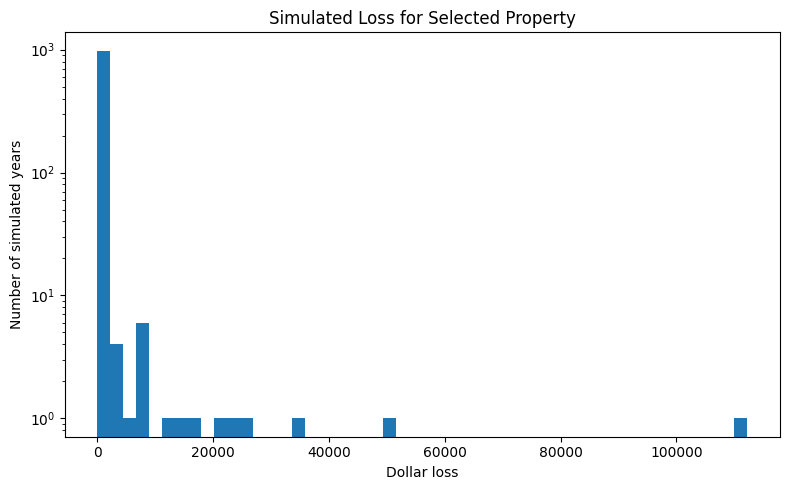

In [60]:
plt.figure(figsize=(8,5))
plt.hist(dollarLosses, bins=50)
plt.yscale("log")
plt.title("Simulated Loss for Selected Property")
plt.xlabel("Dollar loss")
plt.ylabel("Number of simulated years")
plt.tight_layout()
plt.show()

In [64]:
yearlyTotalDollarLosses = DollarLosses.sum(axis=1)
yearlyTotalDollarPercentileLosses = np.quantile(yearlyTotalDollarLosses, percentile, method="hazen")
print("Total Dollar Loss at 99.99th Percentile:", yearlyTotalDollarPercentileLosses)

Total Dollar Loss at 99.99th Percentile: 269381.3650954582


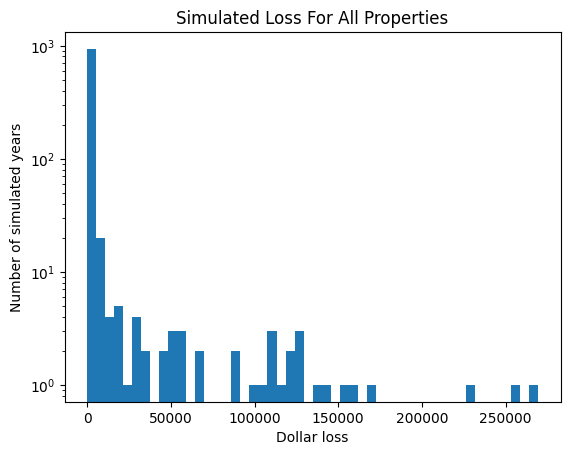

In [65]:
plt.figure()
plt.hist(yearlyTotalDollarLosses, bins=50)
plt.yscale("log")
plt.title("Simulated Loss For All Properties")
plt.xlabel("Dollar loss")
plt.ylabel("Number of simulated years")
plt.show()

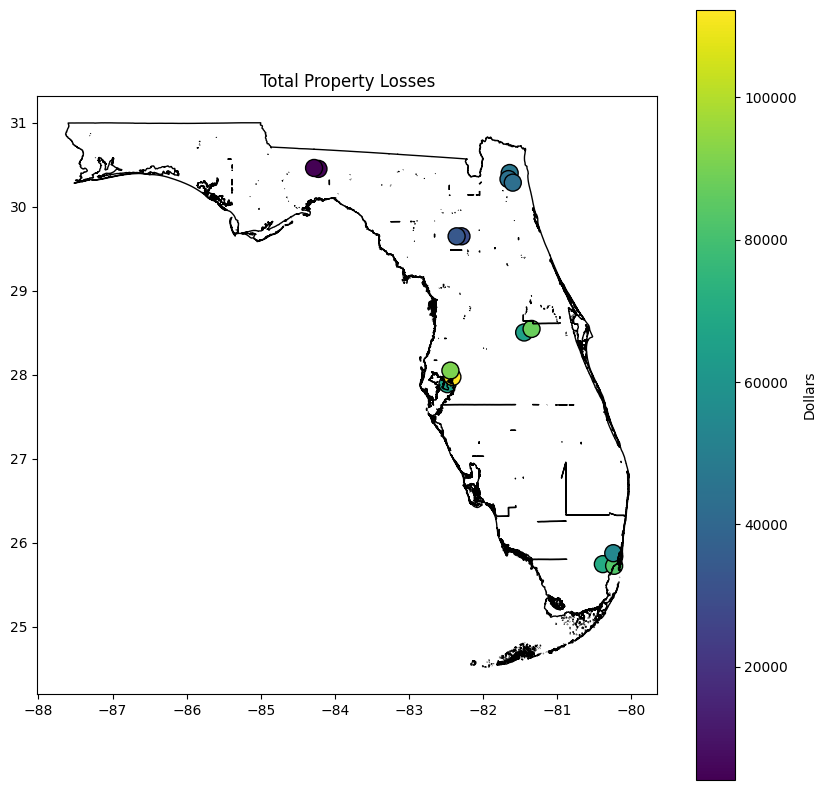

In [63]:
assets_loss["TotalPercentileLosses"] = np.quantile(DollarLosses, percentile, axis=0, method="hazen")

fig, ax = plt.subplots(figsize=(10, 10))
florida_state.boundary.plot(ax=ax, color="black", linewidth=1)
assets_loss.plot(ax=ax, column="TotalPercentileLosses", cmap="viridis",
                 markersize=150, edgecolor="black", legend=True,
                 legend_kwds={"label": "Dollars"})
ax.set_title("Total Property Losses")
plt.show()

1-in- 10-year portfolio loss: 1,340
1-in- 20-year portfolio loss: 8,844
1-in- 50-year portfolio loss: 88,033
1-in-100-year portfolio loss: 125,419
1-in-250-year portfolio loss: 171,157


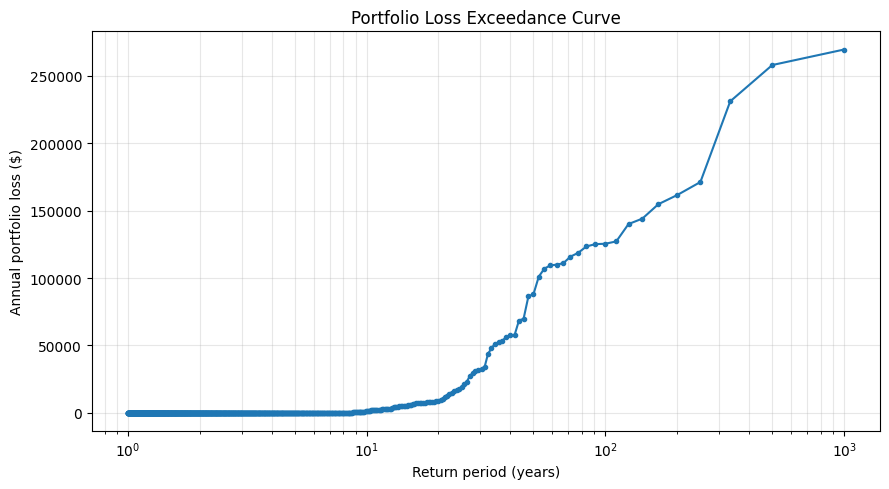

In [66]:
sorted_losses = np.sort(yearlyTotalDollarLosses.values)[::-1]
exceed_prob = np.arange(1, len(sorted_losses) + 1) / len(sorted_losses)
return_period = 1 / exceed_prob

for rp in [10, 20, 50, 100, 250]:
    print(f"1-in-{rp:>3}-year portfolio loss: {np.interp(rp, return_period[::-1], sorted_losses[::-1]):,.0f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(return_period, sorted_losses, marker=".")
ax.set_xscale("log")
ax.set_xlabel("Return period (years)")
ax.set_ylabel("Annual portfolio loss ($)")
ax.set_title("Portfolio Loss Exceedance Curve")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()